In [1]:
import jspec

%matplotlib widget

marking the 5 strongest of 340 features (S/N > 43); raise max_labels or set label_snr to change that


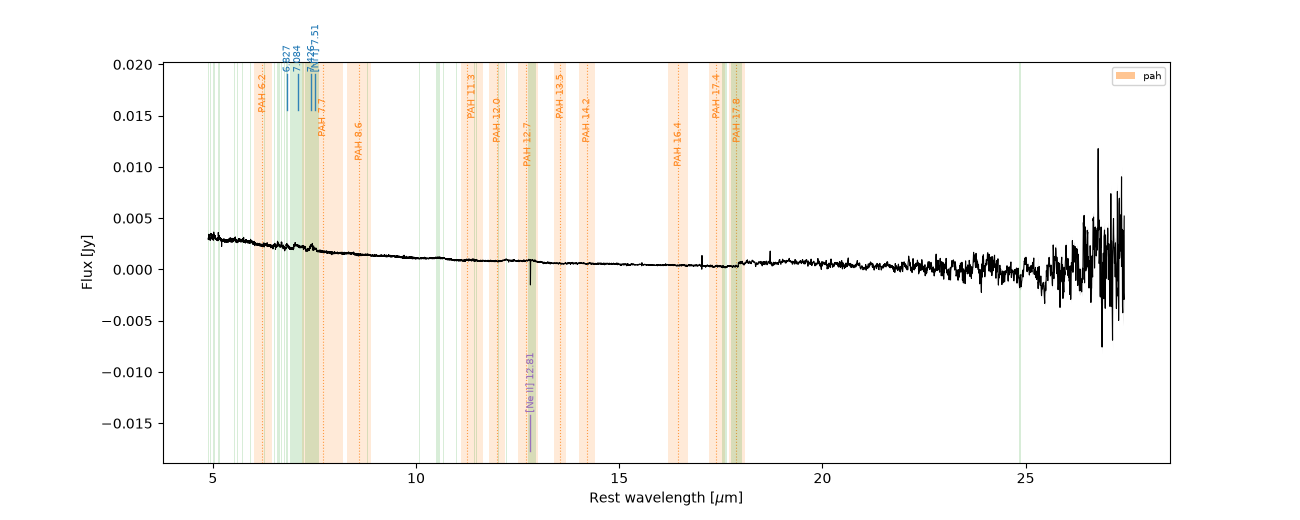

In [11]:
fig, ax = jspec.quicklook(
    "SN2024aecx/SN2024aecx_2025-01-16.ecsv",
    features="SN2024aecx/SN2024aecx_2025-01-16_features.ecsv",
    kinds=["pah", "silicates"],
    max_labels=5)

<>:9: SyntaxWarning: invalid escape sequence '\s'
<>:10: SyntaxWarning: invalid escape sequence '\s'
<>:9: SyntaxWarning: invalid escape sequence '\s'
<>:10: SyntaxWarning: invalid escape sequence '\s'
/var/folders/94/p5d5d_l17m758gxs1qvvbjzw00067m/T/ipykernel_85365/1300481396.py:9: SyntaxWarning: invalid escape sequence '\s'
  feat_df = pd.read_csv(features, comment='#', sep='\s+')
/var/folders/94/p5d5d_l17m758gxs1qvvbjzw00067m/T/ipykernel_85365/1300481396.py:10: SyntaxWarning: invalid escape sequence '\s'
  spec_df = pd.read_csv(spectrum, comment='#', sep='\s+')


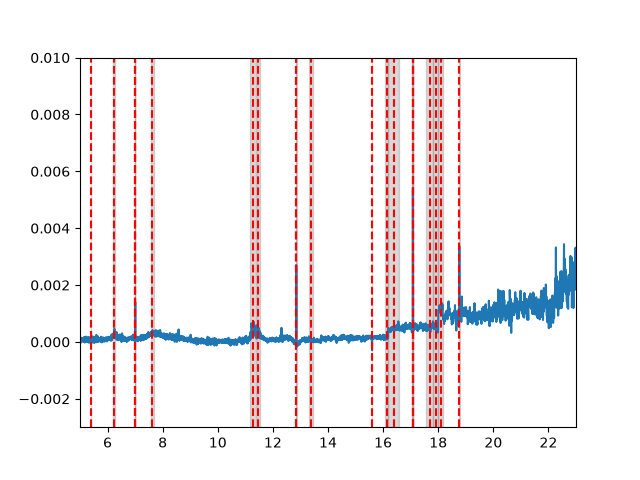

In [24]:
import pandas as pd
import matplotlib.pyplot as plt

%matplotlib widget

features = '/Users/zalane/Modules/JSpec/SN2024aecx/SN2024aecx_2025-12-07_features.ecsv'
spectrum = '/Users/zalane/Modules/JSpec/SN2024aecx/SN2024aecx_2025-12-07.ecsv'

feat_df = pd.read_csv(features, comment='#', sep='\s+')
spec_df = pd.read_csv(spectrum, comment='#', sep='\s+')

feat_df_filtered = feat_df[(feat_df['peak_snr'] > 20) & (feat_df['on_join'] == False)]

feat_df_filtered = feat_df_filtered.reset_index(drop=True)


plt.figure()
plt.plot(spec_df['WAVELENGTH'], spec_df['FLUX'])

for line_i in range(len(feat_df_filtered)):
    plt.axvspan(feat_df_filtered.iloc[line_i]['lo_um'], feat_df_filtered.iloc[line_i]['hi_um'], 
                color='gray', alpha=0.3)
    plt.axvline(x=feat_df_filtered.iloc[line_i]['center_um'], color='r', linestyle='--')

plt.xlim(5, 23)
plt.ylim(-0.003, 0.01)
plt.show()


,rest_center_um,center_um,center_err_um,lo_um,hi_um,component,sign,peak_snr,integrated_snr,flux,...,width_class,resolution_fwhm_kms,on_join,join_fraction,segments,best_id,best_id_species,best_id_velocity_kms,n_candidates,bands
15,5.387325,5.401682,0.000186,5.381200,5.416400,broad,emission,24.599355,15.915625,2.036106e-06,...,narrow,84.379082,False,0.0,SN2024aecx_2025-12-07_abi_combined,NaN,NaN,NaN,0,Amorphous carbon;CO fundamental
47,6.230201,6.246804,0.000175,6.210800,6.279600,broad,emission,33.666643,29.320771,6.364134e-06,...,narrow,84.956558,False,0.0,SN2024aecx_2025-12-07_abi_combined,NaN,NaN,NaN,0,Amorphous carbon;H2O bending;H2O ice 6.0;PAH 6.2
75,6.982347,7.000955,0.000033,6.999200,7.002400,narrow,absorption,23.078583,15.732235,-6.405298e-07,...,narrow,90.450063,False,0.0,SN2024aecx_2025-12-07_abi_combined,[Ar II] 6.99,[Ar II],-129.735767,1,Amorphous carbon;H2O bending
76,6.985667,7.004284,0.000025,6.996000,7.011200,broad,emission,91.435100,43.940003,3.294172e-06,...,narrow,90.408715,False,0.0,SN2024aecx_2025-12-07_abi_combined,[Ar II] 6.99,[Ar II],12.752064,1,Amorphous carbon;H2O bending
77,6.989322,7.007949,0.000048,7.006400,7.010400,narrow,absorption,20.620193,14.202591,-6.260563e-07,...,narrow,90.363237,False,0.0,SN2024aecx_2025-12-07_abi_combined,[Ar II] 6.99,[Ar II],169.622207,1,Amorphous carbon;H2O bending
94,7.594243,7.614482,0.000203,7.563950,7.670550,broad,emission,22.927487,22.451109,5.147058e-06,...,broad,83.418733,False,0.0,SN2024aecx_2025-12-07_abi_combined,NaN,NaN,NaN,0,Amorphous carbon;PAH 7.7;SiO fundamental
171,11.255438,11.285434,0.000167,11.179350,11.402950,broad,emission,48.129108,88.451566,5.558765e-05,...,broad,93.936920,False,0.0,SN2024aecx_2025-12-07_abi_combined,NaN,NaN,NaN,0,Amorphous carbon;Silicate 9.7;AlO fundamental;...
172,11.436039,11.466516,0.000225,11.410750,11.534250,broad,emission,27.211362,37.659089,1.388997e-05,...,broad,92.561403,False,0.0,SN2024aecx_2025-12-07_abi_combined,[Ca V] 11.48,[Ca V],-1200.020733,1,Amorphous carbon;Silicate 9.7;AlO fundamental;...
192,12.809525,12.843663,0.000103,12.838750,12.846250,narrow,absorption,27.460923,16.372370,-2.398312e-06,...,unresolved,108.391737,False,0.0,SN2024aecx_2025-12-07_abi_combined,[Ne II] 12.81,[Ne II],-94.167063,1,Amorphous carbon;H2O ice 13;PAH 12.7;SiS funda...
193,12.815351,12.849504,0.000042,12.838750,12.858750,broad,emission,98.034397,50.423828,8.952685e-06,...,narrow,108.350023,False,0.0,SN2024aecx_2025-12-07_abi_combined,[Ne II] 12.81,[Ne II],42.136884,1,Amorphous carbon;H2O ice 13;PAH 12.7;SiS funda...


In [25]:
from jspec.fitting import load_fit


r = load_fit("ne2.npz")

r.velocity, r.flux, r.flux_err   # data
r.model, r.continuum             # median model
r.components                     # list, one curve per component
r.derived, r.best, r.lo, r.hi    # velocities, FWHM, +/- 1 sigma
r.samples, r.param_names         # for corner plots

(array([[ 2.63560000e-03,  1.25777558e+01,  3.19034364e+01,
         -5.64363445e-05,  5.73067715e-09,  9.99609174e-01],
        [ 5.51176703e-03,  1.22175724e+01,  1.90383902e+01,
         -6.32501016e-05,  8.09850724e-09,  9.61886654e-01],
        [ 2.32019865e-03,  1.28420756e+01,  4.46169051e+01,
         -6.44776538e-05,  9.31981672e-09,  9.77364813e-01],
        ...,
        [ 1.34470585e-03,  3.20675002e+01,  5.58111264e+01,
         -6.11767732e-05,  6.43889605e-09,  9.85648732e-01],
        [ 7.77732989e-03, -6.62295567e+00,  2.43891982e+01,
         -6.13550400e-05,  5.76695135e-09,  9.98649474e-01],
        [ 7.66795122e-03, -2.69777118e+00,  1.90446925e+01,
         -5.44858062e-05,  4.54690035e-09,  9.88871557e-01]],
       shape=(28525, 6)),
 ['amp0', 'v0_kms', 'sigma0_kms', 'cont0', 'cont1', 'err_inflation'])

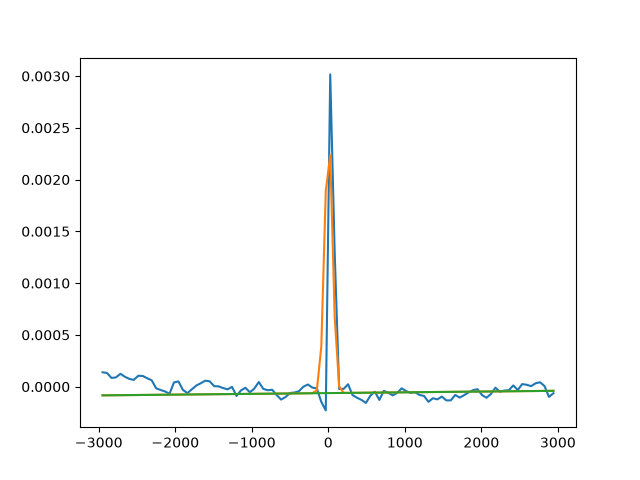

In [29]:
plt.figure()
plt.plot(r.velocity, r.flux, label="Data")
plt.plot(r.velocity, r.model, label="Model")
plt.plot(r.velocity, r.continuum, label="Continuum")
plt.show()